# Benchmark de PosFormer en GPU: latencia y métricas complementarias

Evalúa PosFormer sobre CROHME 2014 sin `torch.profiler`. Cada ejecución representa una corrida completa identificada por `RUN_ID`. Ejecute `run_01`, `run_02` y `run_03`, reiniciando el kernel antes de cada una. La lectura, el preprocesamiento, la decodificación y las métricas quedan fuera del intervalo cronometrado.

In [1]:
from pathlib import Path
from datetime import datetime
import gc, hashlib, json, platform, sys, time
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

def find_project_root():
    for candidate in [Path.cwd(), *Path.cwd().parents, Path.cwd() / '..', Path.cwd() / '../..']:
        candidate = candidate.resolve()
        if (candidate / 'PosFormer').is_dir() and (candidate / 'data').is_dir(): return candidate
    raise FileNotFoundError('No se encontró la raíz con PosFormer/ y data/.')

def file_sha256(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b''): digest.update(chunk)
    return digest.hexdigest()

ROOT = find_project_root(); POS_ROOT = ROOT / 'PosFormer'
RESULTS_DIR = ROOT / 'Cascada' / '01_seleccion' / 'resultados'; RESULTS_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda:0'); assert torch.cuda.is_available(), 'CUDA no está disponible.'
print('Raíz:', ROOT); print('GPU:', torch.cuda.get_device_name(0)); print('PyTorch:', torch.__version__)

Raíz: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
PyTorch: 2.0.1+cu118


## Carga del modelo y utilidades

In [2]:
sys.path.insert(0, str(POS_ROOT))
from Pos_Former.lit_posformer import LitPosFormer
from Pos_Former.datamodule.transforms import ScaleToLimitRange
from Pos_Former.datamodule import vocab
checkpoints = sorted((POS_ROOT / 'lightning_logs' / 'version_0' / 'checkpoints').glob('*.ckpt'))
if not checkpoints: raise FileNotFoundError('No se encontró un checkpoint de PosFormer.')
checkpoint_path = next((path for path in checkpoints if path.name == 'best.ckpt'), checkpoints[0]).resolve()
checkpoint_sha256 = file_sha256(checkpoint_path)
model = LitPosFormer.load_from_checkpoint(str(checkpoint_path), map_location='cpu')
model = model.to(DEVICE).eval().requires_grad_(False); torch.cuda.synchronize()
parameter_count = sum(p.numel() for p in model.parameters())
parameter_bytes = sum(p.numel() * p.element_size() for p in model.parameters())
buffer_bytes = sum(b.numel() * b.element_size() for b in model.buffers())
model_allocated_mib = torch.cuda.memory_allocated() / 1024**2
print('Checkpoint:', checkpoint_path); print('SHA-256:', checkpoint_sha256)
print(f'Parámetros: {parameter_count:,} | pesos + buffers: {(parameter_bytes + buffer_bytes) / 1024**2:.2f} MiB')

/home/mora/miniconda3/envs/hmer-gpu/lib/python3.8/site-packages/pytorch_lightning/utilities/migration/migration.py:203: PossibleUserWarning: You have multiple `ModelCheckpoint` callback states in this checkpoint, but we found state keys that would end up colliding with each other after an upgrade, which means we can't differentiate which of your checkpoint callbacks needs which states. At least one of your `ModelCheckpoint` callbacks will not be able to reload the state.
  rank_zero_warn(
Lightning automatically upgraded your loaded checkpoint from v1.4.9 to v2.0.9. To apply the upgrade to your files permanently, run `python -m pytorch_lightning.utilities.upgrade_checkpoint --file ../../PosFormer/lightning_logs/version_0/checkpoints/best.ckpt`


Checkpoint: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/PosFormer/lightning_logs/version_0/checkpoints/best.ckpt
SHA-256: 943d3d28c7302a2153bfeba87958b2fb48718b55d39b6a8eed234a818360ab71
Parámetros: 9,632,236 | pesos + buffers: 37.77 MiB


In [3]:
scale_transform = ScaleToLimitRange(w_lo=16, w_hi=1024, h_lo=16, h_hi=256)
def prepare_image(path):
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if image is None: raise FileNotFoundError(path)
    original_h, original_w = image.shape; transformed = scale_transform(image)
    tensor = torch.from_numpy(transformed.copy()).float().div_(255).unsqueeze(0).unsqueeze(0)
    _, _, height, width = tensor.shape; mask = torch.zeros((1, height, width), dtype=torch.bool)
    resized = (original_h, original_w) != (height, width)
    return tensor.to(DEVICE), mask.to(DEVICE), (original_h, original_w), (height, width), resized

def prediction_to_latex(hypotheses):
    if hypotheses is None or len(hypotheses) == 0: return '<sin hipótesis>'
    return vocab.indices2label(hypotheses[0].seq)

def token_edit_distance(reference, prediction):
    previous = list(range(len(prediction) + 1))
    for row_index, reference_token in enumerate(reference, start=1):
        current = [row_index]
        for column_index, prediction_token in enumerate(prediction, start=1):
            current.append(min(current[-1] + 1, previous[column_index] + 1, previous[column_index - 1] + (reference_token != prediction_token)))
        previous = current
    return previous[-1]

## Configuración de la corrida

Cambie `RUN_ID` y reinicie el kernel antes de cada corrida. Complete `EXECUTION_CONDITIONS`. La protección contra sobrescritura está activa por defecto.

In [4]:
YEAR = '2014'
RUN_ID = 'run_03'
EXPECTED_RUN_IDS = ('run_01', 'run_02', 'run_03')
ALLOW_OVERWRITE = False
EXECUTION_CONDITIONS = 'PENDIENTE_DE_DOCUMENTAR'
MAX_SAMPLES = None
WARMUP_RUNS = 3
PROGRESS_EVERY = 25
if RUN_ID not in EXPECTED_RUN_IDS: raise ValueError(f'RUN_ID debe ser uno de {EXPECTED_RUN_IDS}.')
run_started_at = datetime.now().astimezone().isoformat(timespec='seconds')
csv_path = RESULTS_DIR / f'benchmark_posformer_latencia_crohme_{YEAR}_{RUN_ID}.csv'
json_path = RESULTS_DIR / f'resumen_posformer_latencia_crohme_{YEAR}_{RUN_ID}.json'
plot_path = RESULTS_DIR / f'benchmark_posformer_latencia_crohme_{YEAR}_{RUN_ID}.png'
existing_outputs = [path for path in (csv_path, json_path, plot_path) if path.exists()]
if existing_outputs and not ALLOW_OVERWRITE:
    raise FileExistsError('Ya existen salidas para esta corrida: ' + ', '.join(str(path) for path in existing_outputs))
split_dir = ROOT / 'data' / 'Modelo2' / YEAR
samples = []
for line in (split_dir / 'caption.txt').read_text(encoding='utf-8').splitlines():
    parts = line.strip().split()
    if parts:
        sample_id = parts[0][:-4] if parts[0].endswith('.jpg') else parts[0]
        samples.append((sample_id, ' '.join(parts[1:])))
if MAX_SAMPLES is not None: samples = samples[:MAX_SAMPLES]
if not samples: raise RuntimeError('No hay muestras para evaluar.')
print(f'Corrida: {RUN_ID} | muestras: {len(samples)} | CROHME {YEAR}')
warm_image, warm_mask, _, _, _ = prepare_image(split_dir / 'img' / f'{samples[0][0]}.bmp')
with torch.inference_mode():
    for _ in range(WARMUP_RUNS):
        warm_output = model.approximate_joint_search(warm_image, warm_mask); torch.cuda.synchronize(); del warm_output
del warm_image, warm_mask; gc.collect(); torch.cuda.synchronize()
print(f'Warm-up terminado: {WARMUP_RUNS} ejecuciones.')

Corrida: run_03 | muestras: 986 | CROHME 2014


/home/mora/miniconda3/envs/hmer-gpu/lib/python3.8/site-packages/torch/nn/modules/conv.py:459: UserWarning: Applied workaround for CuDNN issue, install nvrtc.so (Triggered internally at ../aten/src/ATen/native/cudnn/Conv_v8.cpp:80.)
  return F.conv2d(input, weight, bias, self.stride,


Warm-up terminado: 3 ejecuciones.


## Inferencia y medición

In [5]:
rows = []
for index, (sample_id, ground_truth) in enumerate(samples, start=1):
    path = split_dir / 'img' / f'{sample_id}.bmp'
    row = {'index': index, 'run_id': RUN_ID, 'sample_id': sample_id, 'image_file': path.name, 'ground_truth': ground_truth, 'status': 'ok', 'error': ''}
    try:
        image, mask, (height, width), (model_height, model_width), resized = prepare_image(path)
        gc.collect(); torch.cuda.synchronize()
        baseline = torch.cuda.memory_allocated(); torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
        start = time.perf_counter()
        with torch.inference_mode(): hypotheses = model.approximate_joint_search(image, mask)
        torch.cuda.synchronize(); elapsed_ms = (time.perf_counter() - start) * 1000.0
        peak = torch.cuda.max_memory_allocated(); prediction = prediction_to_latex(hypotheses)
        ground_truth_tokens, prediction_tokens = ground_truth.strip().split(), prediction.strip().split()
        edit_distance = token_edit_distance(ground_truth_tokens, prediction_tokens)
        row.update({'height': height, 'width': width, 'model_height': model_height, 'model_width': model_width, 'resized': int(resized), 'prediction': prediction, 'correct': int(edit_distance == 0), 'edit_distance': edit_distance, 'edit_distance_le_1': int(edit_distance <= 1), 'edit_distance_le_2': int(edit_distance <= 2), 'ground_truth_token_count': len(ground_truth_tokens), 'prediction_token_count': len(prediction_tokens), 'cer': edit_distance / max(len(ground_truth_tokens), 1), 'latency_ms': elapsed_ms, 'base_mib': baseline / 1024**2, 'peak_total_mib': peak / 1024**2, 'peak_increment_mib': (peak - baseline) / 1024**2})
        del hypotheses, image, mask
    except Exception as exc:
        row.update({'status': 'error', 'error': f'{type(exc).__name__}: {exc}', 'correct': np.nan, 'latency_ms': np.nan, 'peak_total_mib': np.nan, 'peak_increment_mib': np.nan})
        if 'out of memory' in str(exc).lower(): rows.append(row); raise
    rows.append(row); gc.collect()
    if index == 1 or index % PROGRESS_EVERY == 0 or index == len(samples):
        valid_now = [item['latency_ms'] for item in rows if item['status'] == 'ok']
        print(f'{index:4d}/{len(samples)} | válidas={len(valid_now):4d} | latencia media={np.mean(valid_now):.2f} ms')

   1/986 | válidas=   1 | latencia media=55.60 ms
  25/986 | válidas=  25 | latencia media=303.71 ms
  50/986 | válidas=  50 | latencia media=225.26 ms
  75/986 | válidas=  75 | latencia media=221.51 ms
 100/986 | válidas= 100 | latencia media=199.78 ms
 125/986 | válidas= 125 | latencia media=186.36 ms
 150/986 | válidas= 150 | latencia media=178.71 ms
 175/986 | válidas= 175 | latencia media=175.68 ms
 200/986 | válidas= 200 | latencia media=171.11 ms
 225/986 | válidas= 225 | latencia media=168.98 ms
 250/986 | válidas= 250 | latencia media=169.49 ms
 275/986 | válidas= 275 | latencia media=170.10 ms
 300/986 | válidas= 300 | latencia media=173.50 ms
 325/986 | válidas= 325 | latencia media=175.27 ms
 350/986 | válidas= 350 | latencia media=176.04 ms
 375/986 | válidas= 375 | latencia media=180.26 ms
 400/986 | válidas= 400 | latencia media=184.74 ms
 425/986 | válidas= 425 | latencia media=189.69 ms
 450/986 | válidas= 450 | latencia media=193.57 ms
 475/986 | válidas= 475 | latenc

## Resumen de la corrida

,valor
model,PosFormer
run_id,run_03
run_started_at,2026-11-11T18:12:03-06:00
run_finished_at,2026-11-11T18:23:21-06:00
execution_conditions,PENDIENTE_DE_DOCUMENTAR
dataset,CROHME 2014
checkpoint,/mnt/c/Users/novac/Documents/Unidad/Documentos...
checkpoint_sha256,943d3d28c7302a2153bfeba87958b2fb48718b55d39b6a...
samples_requested,986
samples_valid,986


CSV: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/01_seleccion/resultados/benchmark_posformer_latencia_crohme_2014_run_03.csv
Resumen: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/01_seleccion/resultados/resumen_posformer_latencia_crohme_2014_run_03.json


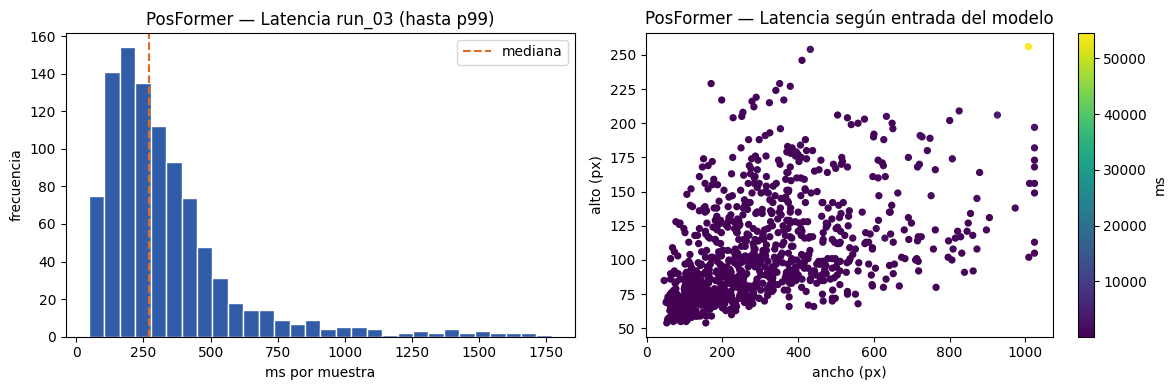

Gráfica: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/01_seleccion/resultados/benchmark_posformer_latencia_crohme_2014_run_03.png


In [6]:
results = pd.DataFrame(rows); valid = results.loc[results['status'] == 'ok'].copy()
if valid.empty: raise RuntimeError('No hubo mediciones válidas.')
latencies = valid['latency_ms'].to_numpy(dtype=np.float64); total_seconds = float(latencies.sum() / 1000.0)
total_edit_distance = int(valid['edit_distance'].sum()); total_reference_tokens = int(valid['ground_truth_token_count'].sum())
exact_match_count = int(valid['correct'].sum()); le1_count = int(valid['edit_distance_le_1'].sum()); le2_count = int(valid['edit_distance_le_2'].sum())
_, gpu_total_bytes = torch.cuda.mem_get_info()
summary = {
    'model': 'PosFormer', 'run_id': RUN_ID, 'run_started_at': run_started_at, 'run_finished_at': datetime.now().astimezone().isoformat(timespec='seconds'), 'execution_conditions': EXECUTION_CONDITIONS,
    'dataset': f'CROHME {YEAR}', 'checkpoint': str(checkpoint_path), 'checkpoint_sha256': checkpoint_sha256, 'samples_requested': len(samples), 'samples_valid': len(valid), 'errors': int((results['status'] != 'ok').sum()),
    'exact_match_count': exact_match_count, 'exact_match_percent': float(100 * exact_match_count / len(valid)), 'edit_distance_le_1_count': le1_count, 'edit_distance_le_1_percent': float(100 * le1_count / len(valid)), 'edit_distance_le_2_count': le2_count, 'edit_distance_le_2_percent': float(100 * le2_count / len(valid)),
    'cer_micro_percent': float(100 * total_edit_distance / total_reference_tokens), 'cer_macro_percent': float(100 * valid['cer'].mean()), 'total_edit_distance': total_edit_distance, 'total_reference_tokens': total_reference_tokens, 'cer_unit': 'tokens LaTeX separados por espacios',
    'latency_mean_ms': float(np.mean(latencies)), 'latency_median_ms': float(np.median(latencies)), 'latency_p95_ms': float(np.percentile(latencies, 95)), 'latency_p99_ms': float(np.percentile(latencies, 99)), 'latency_min_ms': float(np.min(latencies)), 'latency_max_ms': float(np.max(latencies)), 'total_inference_seconds': total_seconds, 'total_inference_minutes': total_seconds / 60.0, 'throughput_images_per_second': len(valid) / total_seconds,
    'parameters': parameter_count, 'parameters_millions': parameter_count / 1e6, 'weights_buffers_mib': (parameter_bytes + buffer_bytes) / 1024**2, 'model_allocated_mib': model_allocated_mib, 'max_peak_total_mib': float(valid['peak_total_mib'].max()), 'max_peak_increment_mib': float(valid['peak_increment_mib'].max()), 'resized_samples': int(valid['resized'].sum()),
    'gpu': torch.cuda.get_device_name(0), 'gpu_total_mib': gpu_total_bytes / 1024**2, 'python': platform.python_version(), 'pytorch': torch.__version__, 'cuda': torch.version.cuda, 'warmup_runs': WARMUP_RUNS, 'timing_scope': 'Solo approximate_joint_search(image, mask) en GPU; excluye lectura, preprocesamiento, decodificación, métricas y escritura.'}
results.to_csv(csv_path, index=False, encoding='utf-8'); json_path.write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
display(pd.DataFrame([summary]).T.rename(columns={0: 'valor'})); print('CSV:', csv_path); print('Resumen:', json_path)
fig, axes = plt.subplots(1, 2, figsize=(12, 4)); display_limit = np.percentile(latencies, 99)
axes[0].hist(valid.loc[valid['latency_ms'] <= display_limit, 'latency_ms'], bins=30, color='#315da8', edgecolor='white'); axes[0].axvline(summary['latency_median_ms'], color='#dd6b20', linestyle='--', label='mediana'); axes[0].set(title=f'PosFormer — Latencia {RUN_ID} (hasta p99)', xlabel='ms por muestra', ylabel='frecuencia'); axes[0].legend()
scatter = axes[1].scatter(valid['model_width'], valid['model_height'], c=valid['latency_ms'], cmap='viridis', s=18); axes[1].set(title='PosFormer — Latencia según entrada del modelo', xlabel='ancho (px)', ylabel='alto (px)'); fig.colorbar(scatter, ax=axes[1], label='ms')
fig.tight_layout(); fig.savefig(plot_path, dpi=160, bbox_inches='tight'); plt.show(); print('Gráfica:', plot_path)

## Agregación de las tres corridas

In [7]:
summary_paths = {run_id: RESULTS_DIR / f'resumen_posformer_latencia_crohme_{YEAR}_{run_id}.json' for run_id in EXPECTED_RUN_IDS}
available = [json.loads(path.read_text(encoding='utf-8')) for path in summary_paths.values() if path.exists()]
if not available:
    print('Todavía no hay corridas guardadas.')
else:
    run_table = pd.DataFrame(available).sort_values('run_id')
    display(run_table[['run_id', 'latency_mean_ms', 'latency_median_ms', 'latency_p95_ms', 'total_inference_seconds', 'samples_valid', 'errors', 'execution_conditions']])
    missing = [run_id for run_id, path in summary_paths.items() if not path.exists()]
    if missing:
        print('Faltan corridas:', ', '.join(missing))
    else:
        consistency_fields = ['samples_requested', 'samples_valid', 'errors', 'exact_match_count', 'edit_distance_le_1_count', 'edit_distance_le_2_count', 'total_edit_distance', 'total_reference_tokens', 'checkpoint_sha256', 'gpu', 'pytorch', 'cuda']
        inconsistent = [field for field in consistency_fields if run_table[field].nunique(dropna=False) != 1]
        if inconsistent: raise ValueError('Corridas inconsistentes: ' + ', '.join(inconsistent))
        metrics = ['latency_mean_ms', 'latency_median_ms', 'latency_p95_ms', 'latency_p99_ms', 'total_inference_seconds', 'throughput_images_per_second']
        aggregate = {'model': 'PosFormer', 'dataset': f'CROHME {YEAR}', 'run_ids': list(EXPECTED_RUN_IDS), 'number_of_runs': len(EXPECTED_RUN_IDS), 'aggregation_scope': 'Corridas completas e independientes.'}
        for metric in metrics:
            aggregate[f'{metric}_mean_across_runs'] = float(run_table[metric].mean()); aggregate[f'{metric}_std_across_runs'] = float(run_table[metric].std(ddof=1)); aggregate[f'{metric}_min_across_runs'] = float(run_table[metric].min()); aggregate[f'{metric}_max_across_runs'] = float(run_table[metric].max())
        per_sample, latency_columns = None, []
        for run_id in EXPECTED_RUN_IDS:
            frame = pd.read_csv(RESULTS_DIR / f'benchmark_posformer_latencia_crohme_{YEAR}_{run_id}.csv')
            frame = frame.loc[frame['status'] == 'ok', ['sample_id', 'latency_ms']].copy()
            if frame['sample_id'].duplicated().any(): raise ValueError(f'IDs duplicados en {run_id}.')
            column = f'latency_ms_{run_id}'; latency_columns.append(column); frame = frame.rename(columns={'latency_ms': column})
            per_sample = frame if per_sample is None else per_sample.merge(frame, on='sample_id', how='inner', validate='one_to_one')
        if len(per_sample) != int(run_table.iloc[0]['samples_valid']): raise ValueError('Las corridas no contienen los mismos IDs válidos.')
        per_sample['latency_mean_ms'] = per_sample[latency_columns].mean(axis=1); per_sample['latency_median_ms'] = per_sample[latency_columns].median(axis=1); per_sample['latency_std_ms'] = per_sample[latency_columns].std(axis=1, ddof=1); per_sample['latency_min_ms'] = per_sample[latency_columns].min(axis=1); per_sample['latency_max_ms'] = per_sample[latency_columns].max(axis=1); per_sample['measurement_count'] = per_sample[latency_columns].count(axis=1)
        aggregate_json = RESULTS_DIR / f'resumen_posformer_latencia_crohme_{YEAR}_repeticiones.json'; aggregate_csv = RESULTS_DIR / f'resumen_posformer_latencia_crohme_{YEAR}_repeticiones.csv'; per_sample_csv = RESULTS_DIR / f'benchmark_posformer_latencia_crohme_{YEAR}_repeticiones_por_muestra.csv'
        aggregate_json.write_text(json.dumps(aggregate, ensure_ascii=False, indent=2), encoding='utf-8'); pd.DataFrame([aggregate]).to_csv(aggregate_csv, index=False, encoding='utf-8'); per_sample.to_csv(per_sample_csv, index=False, encoding='utf-8')
        display(pd.DataFrame([aggregate]).T.rename(columns={0: 'valor'})); print('Resumen agregado:', aggregate_json); print('Por muestra:', per_sample_csv)

,run_id,latency_mean_ms,latency_median_ms,latency_p95_ms,total_inference_seconds,samples_valid,errors,execution_conditions
0,run_01,415.373803,262.326313,936.335494,409.558569,986,0,PENDIENTE_DE_DOCUMENTAR
1,run_02,405.211080,267.364595,861.273673,399.538125,986,0,PENDIENTE_DE_DOCUMENTAR
2,run_03,413.205542,270.284310,949.167377,407.420664,986,0,PENDIENTE_DE_DOCUMENTAR


,valor
model,PosFormer
dataset,CROHME 2014
run_ids,"[run_01, run_02, run_03]"
number_of_runs,3
aggregation_scope,Corridas completas e independientes.
latency_mean_ms_mean_across_runs,411.263475
latency_mean_ms_std_across_runs,5.352472
latency_mean_ms_min_across_runs,405.21108
latency_mean_ms_max_across_runs,415.373803
latency_median_ms_mean_across_runs,266.658406


Resumen agregado: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/01_seleccion/resultados/resumen_posformer_latencia_crohme_2014_repeticiones.json
Por muestra: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/01_seleccion/resultados/benchmark_posformer_latencia_crohme_2014_repeticiones_por_muestra.csv


## Notas

Cada corrida debe ejecutarse en un kernel nuevo. Los archivos agregados solo se generan cuando existen las tres corridas y coinciden en muestras, reconocimiento, checkpoint y entorno. No se calculan FLOPs.